# Does Tuning Improve XGBoost Beyond the Fixed Configuration?

Notebook 26 found that one fixed XGBoost configuration improved route-level RMSE over dynamic Ridge. This experiment asks whether a small, prespecified hyperparameter search improves that result. It uses nested game-grouped validation: five outer folds provide held-out predictions, while three inner folds within each outer training set select from 12 deterministic configurations. Early stopping sees only inner validation games. The outer held-out games never select parameters or boosting rounds.

Every model uses the same 2021 WR route rows and dynamic feature block. The comparison includes the previous fixed XGBoost configuration, so we can separate the value of tuning from the value of switching algorithms. Receiver repeatability and calibration are reported as secondary diagnostics, not tuning objectives.

In [1]:
from pathlib import Path
import math
import sys

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from IPython.display import SVG, display
from separation_over_expected.reports import read_csv_rows, write_csv
from separation_over_expected.xgboost_tuning import tune_xgboost_nested

ROUTE_TABLE = PROJECT_ROOT / "data/processed/dynamic_features/pocket_context/route_level_snap_to_release_pocket.csv"
OUTPUT_DIR = PROJECT_ROOT / "data/processed/xgboost_tuning"
OUTPUT_FILES = {
    "predictions": OUTPUT_DIR / "route_oof_predictions.csv",
    "metrics": OUTPUT_DIR / "candidate_metrics.csv",
    "folds": OUTPUT_DIR / "outer_fold_metrics.csv",
    "calibration": OUTPUT_DIR / "calibration_deciles.csv",
    "search": OUTPUT_DIR / "inner_search_results.csv",
    "selected": OUTPUT_DIR / "selected_outer_configs.csv",
    "reliability": OUTPUT_DIR / "receiver_reliability.csv",
}

if all(path.exists() for path in OUTPUT_FILES.values()):
    tables = {name: read_csv_rows(path) for name, path in OUTPUT_FILES.items()}
else:
    if not ROUTE_TABLE.exists():
        raise FileNotFoundError("Build the 2021 dynamic route table with pocket-context fields first.")
    result = tune_xgboost_nested(
        read_csv_rows(ROUTE_TABLE),
        outer_folds=5,
        inner_folds=3,
        bootstrap_samples=1000,
        min_routes_per_half=20,
        seed=42,
    )
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    tables = dict(zip(OUTPUT_FILES, result))
    for name, rows in tables.items():
        columns = list(dict.fromkeys(key for row in rows for key in row))
        write_csv(OUTPUT_FILES[name], columns, rows)

predictions = tables["predictions"]
metrics = tables["metrics"]
folds = tables["folds"]
calibration = tables["calibration"]
search = tables["search"]
selected = tables["selected"]
reliability = tables["reliability"]
len(predictions), len({(row["week"], row["gameId"]) for row in predictions}), len(search)

(20415, 122, 180)

## What was selected in the inner folds?

Twelve configurations are tested per outer fold, including the previous fixed settings. The search changes tree depth, minimum child weight, learning rate, row and feature sampling, and L1/L2 regularization. Each candidate can grow to 1,500 rounds and stops after 60 rounds without inner-validation RMSE improvement. The selected boosting-round count is the median best iteration across the three inner folds, then the selected configuration is refit on all outer-training games.

In [2]:
selected_table = []
for row in selected:
    selected_table.append({
        "outer fold": row["outer_fold"],
        "selected config": row["selected_config_id"],
        "inner CV RMSE": f'{float(row["inner_mean_rmse"]):.3f}',
        "trees": row["selected_n_estimators"],
        "depth": row["max_depth"],
        "min child weight": row["min_child_weight"],
        "learning rate": f'{float(row["learning_rate"]):.3f}',
        "row sample": f'{float(row["subsample"]):.2f}',
        "feature sample": f'{float(row["colsample_bytree"]):.2f}',
        "L1": row["reg_alpha"],
        "L2": f'{float(row["reg_lambda"]):.2f}',
        "gamma": row["gamma"],
    })
display(selected_table)

[{'outer fold': '1',
  'selected config': '1',
  'inner CV RMSE': '1.815',
  'trees': '308',
  'depth': '5',
  'min child weight': '10',
  'learning rate': '0.040',
  'row sample': '0.80',
  'feature sample': '0.80',
  'L1': '0',
  'L2': '10.00',
  'gamma': '0'},
 {'outer fold': '2',
  'selected config': '1',
  'inner CV RMSE': '1.793',
  'trees': '352',
  'depth': '5',
  'min child weight': '10',
  'learning rate': '0.040',
  'row sample': '0.80',
  'feature sample': '0.80',
  'L1': '0',
  'L2': '10.00',
  'gamma': '0'},
 {'outer fold': '3',
  'selected config': '1',
  'inner CV RMSE': '1.790',
  'trees': '416',
  'depth': '5',
  'min child weight': '10',
  'learning rate': '0.040',
  'row sample': '0.80',
  'feature sample': '0.80',
  'L1': '0',
  'L2': '10.00',
  'gamma': '0'},
 {'outer fold': '4',
  'selected config': '9',
  'inner CV RMSE': '1.765',
  'trees': '826',
  'depth': '4',
  'min child weight': '5',
  'learning rate': '0.026',
  'row sample': '0.81',
  'feature sample': 

## Outer-fold route prediction

The paired game bootstrap resamples the outer held-out games and calculates the difference in pooled RMSE. Negative change favors the candidate. These intervals quantify held-out game variation for this nested selection procedure.

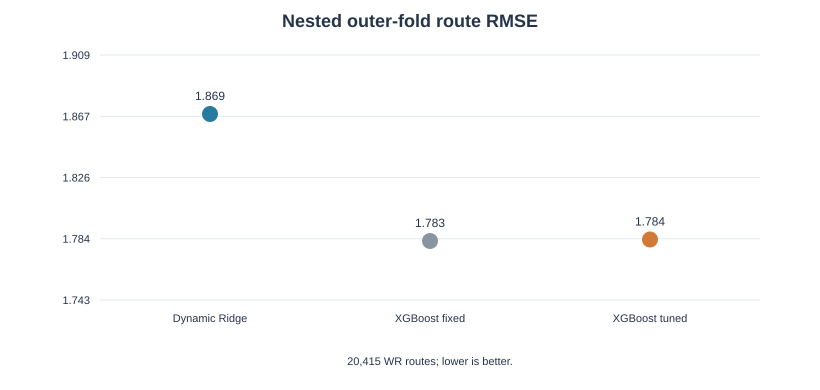

[{'model': 'Dynamic Ridge',
  'RMSE': '1.869',
  'MAE': '1.363',
  'R²': '0.508',
  'RMSE change vs Ridge (95% game bootstrap)': 'baseline',
  'RMSE change vs fixed XGBoost (95% game bootstrap)': 'baseline'},
 {'model': 'XGBoost fixed',
  'RMSE': '1.783',
  'MAE': '1.273',
  'R²': '0.552',
  'RMSE change vs Ridge (95% game bootstrap)': '-0.086 [-0.100, -0.073]',
  'RMSE change vs fixed XGBoost (95% game bootstrap)': 'baseline'},
 {'model': 'XGBoost tuned',
  'RMSE': '1.784',
  'MAE': '1.275',
  'R²': '0.552',
  'RMSE change vs Ridge (95% game bootstrap)': '-0.085 [-0.098, -0.073]',
  'RMSE change vs fixed XGBoost (95% game bootstrap)': '+0.001 [-0.001, +0.004]'}]

In [3]:
models = ["ridge_dynamic_context", "xgboost_fixed", "xgboost_tuned"]
labels = {
    "ridge_dynamic_context": "Dynamic Ridge",
    "xgboost_fixed": "XGBoost fixed",
    "xgboost_tuned": "XGBoost tuned",
}
colors = {
    "ridge_dynamic_context": "#287b9e",
    "xgboost_fixed": "#8895a1",
    "xgboost_tuned": "#d17a36",
}

def model_metric(model):
    return next(row for row in metrics if row["model"] == model)

def route_error_svg(width=820, height=390):
    low = min(float(model_metric(model)["rmse"]) for model in models) - .04
    high = max(float(model_metric(model)["rmse"]) for model in models) + .04
    left, right, top, bottom = 100, 760, 55, 300
    y = lambda value: bottom - (float(value) - low) / (high - low) * (bottom - top)
    xs = [210, 430, 650]
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="white"/>',
        '<style>text{font-family:Arial,sans-serif;fill:#253449}.grid{stroke:#e3e9ef}</style>',
        '<text x="410" y="27" text-anchor="middle" font-size="18" font-weight="bold">Nested outer-fold route RMSE</text>',
    ]
    for index in range(5):
        value = low + (high - low) * index / 4
        yy = y(value)
        parts += [f'<line class="grid" x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}"/>',
                  f'<text x="{left-10}" y="{yy+4:.1f}" text-anchor="end" font-size="11">{value:.3f}</text>']
    for x, model in zip(xs, models):
        row = model_metric(model)
        value = float(row["rmse"])
        parts += [f'<circle cx="{x}" cy="{y(value):.1f}" r="8" fill="{colors[model]}"><title>{labels[model]}: {value:.3f} yd</title></circle>',
                  f'<text x="{x}" y="{y(value)-14:.1f}" text-anchor="middle" font-size="12">{value:.3f}</text>',
                  f'<text x="{x}" y="{bottom+22}" text-anchor="middle" font-size="11">{labels[model]}</text>']
    parts += ['<text x="430" y="365" text-anchor="middle" font-size="11">20,415 WR routes; lower is better.</text>', '</svg>']
    return "".join(parts)

display(SVG(route_error_svg()))
display([{
    "model": labels[model],
    "RMSE": model_metric(model)["rmse"],
    "MAE": model_metric(model)["mae"],
    "R²": model_metric(model)["r2"],
    "RMSE change vs Ridge (95% game bootstrap)": (
        "baseline" if model == "ridge_dynamic_context" else
        f'{float(model_metric(model)["rmse_delta_vs_ridge"]):+.3f} '
        f'[{float(model_metric(model)["rmse_delta_lower_95"]):+.3f}, '
        f'{float(model_metric(model)["rmse_delta_upper_95"]):+.3f}]'
    ),
    "RMSE change vs fixed XGBoost (95% game bootstrap)": (
        "baseline" if model != "xgboost_tuned" else
        f'{float(model_metric(model)["rmse_delta_vs_fixed_xgboost"]):+.3f} '
        f'[{float(model_metric(model)["rmse_delta_vs_fixed_xgboost_lower_95"]):+.3f}, '
        f'{float(model_metric(model)["rmse_delta_vs_fixed_xgboost_upper_95"]):+.3f}]'
    ),
} for model in models])

## Calibration

Compare observed and predicted separation change by out-of-fold prediction decile. Tuning is selected on RMSE only; slope and decile bias are checks against a route-accuracy gain that comes with poor average calibration.

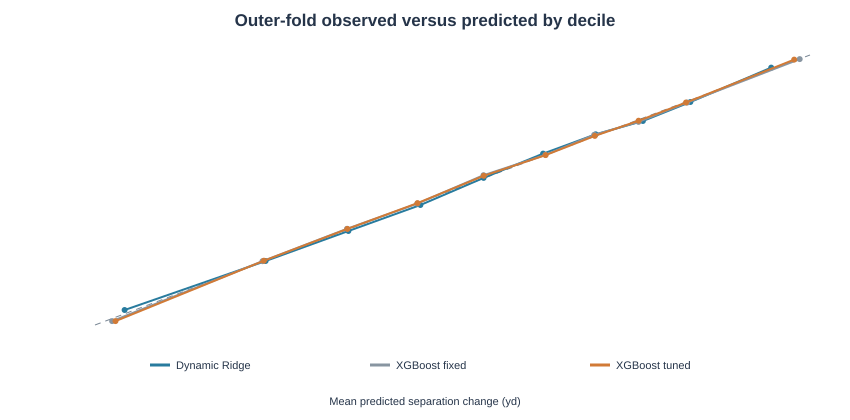

[{'model': 'Dynamic Ridge',
  'slope': 0.997,
  'intercept': -0.006,
  'mean absolute decile bias': 0.051},
 {'model': 'XGBoost fixed',
  'slope': 1.002,
  'intercept': 0.004,
  'mean absolute decile bias': 0.034},
 {'model': 'XGBoost tuned',
  'slope': 1.011,
  'intercept': 0.024,
  'mean absolute decile bias': 0.029}]

In [4]:
def calibration_svg(rows, width=850, height=420):
    low = min(float(row[key]) for row in rows for key in ("mean_actual", "mean_predicted")) - .1
    high = max(float(row[key]) for row in rows for key in ("mean_actual", "mean_predicted")) + .1
    left, right, top, bottom = 95, 810, 55, 325
    x = lambda value: left + (float(value) - low) / (high - low) * (right - left)
    y = lambda value: bottom - (float(value) - low) / (high - low) * (bottom - top)
    pieces = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
              '<rect width="100%" height="100%" fill="white"/>',
              '<style>text{font-family:Arial,sans-serif;fill:#253449}.grid{stroke:#e3e9ef}</style>',
              '<text x="425" y="26" text-anchor="middle" font-size="17" font-weight="bold">Outer-fold observed versus predicted by decile</text>',
              f'<line x1="{x(low):.1f}" y1="{y(low):.1f}" x2="{x(high):.1f}" y2="{y(high):.1f}" stroke="#778593" stroke-dasharray="6 5"/>']
    for model in models:
        grouped = sorted((row for row in rows if row["model"] == model), key=lambda row: int(row["decile"]))
        pts = " ".join(f'{x(row["mean_predicted"]):.1f},{y(row["mean_actual"]):.1f}' for row in grouped)
        pieces.append(f'<polyline points="{pts}" fill="none" stroke="{colors[model]}" stroke-width="2"/>')
        for row in grouped:
            pieces.append(f'<circle cx="{x(row["mean_predicted"]):.1f}" cy="{y(row["mean_actual"]):.1f}" r="3" fill="{colors[model]}"/>')
    for index, model in enumerate(models):
        xx = 150 + index * 220
        pieces += [f'<line x1="{xx}" y1="365" x2="{xx+20}" y2="365" stroke="{colors[model]}" stroke-width="3"/>',
                   f'<text x="{xx+26}" y="369" font-size="11">{labels[model]}</text>']
    pieces += ['<text x="425" y="405" text-anchor="middle" font-size="11">Mean predicted separation change (yd)</text>', '</svg>']
    return "".join(pieces)

display(SVG(calibration_svg(calibration)))
display([{"model": labels[row["model"]], "slope": round(float(row["calibration_slope"]), 3),
          "intercept": round(float(row["calibration_intercept"]), 3),
          "mean absolute decile bias": round(float(row["mean_absolute_decile_bias"]), 3)}
         for row in metrics])

## Receiver residual repeatability

Receiver effects are not the tuning target. This checks whether changing the route model changes split-half Pearson and Spearman repeatability across the same receivers and game halves. The paired interval is especially useful: does tuned XGBoost improve over the fixed XGBoost and over Ridge?

In [5]:
direct_reliability = {row["comparison"]: row for row in reliability if row["comparison"] in models}
delta_rows = [row for row in reliability if "minus" in row["comparison"]]
display([{
    "model": labels[model],
    "eligible receivers": direct_reliability[model]["eligible_receivers"],
    "Pearson": direct_reliability[model]["pearson"],
    "Spearman": direct_reliability[model]["spearman"],
} for model in models])
display([{
    "comparison": row["comparison"],
    "Pearson change": row["pearson"],
    "Pearson 95% interval": f'[{row["pearson_ci_lower"]}, {row["pearson_ci_upper"]}]',
    "Spearman change": row["spearman"],
    "Spearman 95% interval": f'[{row["spearman_ci_lower"]}, {row["spearman_ci_upper"]}]',
} for row in delta_rows])

[{'model': 'Dynamic Ridge',
  'eligible receivers': '115',
  'Pearson': '0.451857',
  'Spearman': '0.209469'},
 {'model': 'XGBoost fixed',
  'eligible receivers': '115',
  'Pearson': '0.457505',
  'Spearman': '0.252387'},
 {'model': 'XGBoost tuned',
  'eligible receivers': '115',
  'Pearson': '0.446769',
  'Spearman': '0.251472'}]

[{'comparison': 'xgboost_fixed_minus_ridge_dynamic_context',
  'Pearson change': '0.005648',
  'Pearson 95% interval': '[-0.107040, 0.105242]',
  'Spearman change': '0.042918',
  'Spearman 95% interval': '[-0.056943, 0.155853]'},
 {'comparison': 'xgboost_tuned_minus_xgboost_fixed',
  'Pearson change': '-0.010736',
  'Pearson 95% interval': '[-0.019374, 0.007416]',
  'Spearman change': '-0.000915',
  'Spearman 95% interval': '[-0.029048, 0.025318]'},
 {'comparison': 'xgboost_tuned_minus_ridge_dynamic_context',
  'Pearson change': '-0.005088',
  'Pearson 95% interval': '[-0.107398, 0.091414]',
  'Spearman change': '0.042003',
  'Spearman 95% interval': '[-0.055050, 0.146214]'}]

## Interpretation

Tuning earns its keep only if it improves the outer-fold result against the previous fixed XGBoost and Ridge, with uncertainty that supports the gain. If route RMSE improves but receiver repeatability remains unchanged, retain tuned XGBoost for route prediction only; this does not validate a receiver ranking. The outer-fold comparison is an internal 2021 estimate, so a winning configuration still needs an untouched later-season check before claiming transfer.

In [6]:
ridge = model_metric("ridge_dynamic_context")
fixed = model_metric("xgboost_fixed")
tuned = model_metric("xgboost_tuned")
tuned_vs_fixed = float(tuned["rmse"]) - float(fixed["rmse"])
tuned_vs_ridge = float(tuned["rmse"]) - float(ridge["rmse"])
tuned_fixed_ci = (
    float(tuned["rmse_delta_vs_fixed_xgboost_lower_95"]),
    float(tuned["rmse_delta_vs_fixed_xgboost_upper_95"]),
)
tuned_ridge_delta = next(row for row in reliability if row["comparison"] == "xgboost_tuned_minus_ridge_dynamic_context")
(
    f"Tuned versus fixed XGBoost: {tuned_vs_fixed:+.3f} yd RMSE "
    f"(paired 95% game-bootstrap interval [{tuned_fixed_ci[0]:+.3f}, {tuned_fixed_ci[1]:+.3f}]).",
    f"Tuned versus Ridge: {tuned_vs_ridge:+.3f} yd RMSE "
    f"(paired 95% game-bootstrap interval [{float(tuned['rmse_delta_lower_95']):+.3f}, {float(tuned['rmse_delta_upper_95']):+.3f}]).",
    f"Tuned receiver Pearson change versus Ridge: {float(tuned_ridge_delta['pearson']):+.3f} "
    f"(95% interval [{float(tuned_ridge_delta['pearson_ci_lower']):+.3f}, {float(tuned_ridge_delta['pearson_ci_upper']):+.3f}]).",
)

('Tuned versus fixed XGBoost: +0.001 yd RMSE (paired 95% game-bootstrap interval [-0.001, +0.004]).',
 'Tuned versus Ridge: -0.085 yd RMSE (paired 95% game-bootstrap interval [-0.098, -0.073]).',
 'Tuned receiver Pearson change versus Ridge: -0.005 (95% interval [-0.107, +0.091]).')